# Problema 1: El reporte demasiado bueno
**Alumno:** Owen Adiel Solis Zatarain  
**Expediente / Semilla:** `223201053` ($a = 3$, $b = 5$)

---

## (a) Reproducir
Abajo está el **código original intacto de la consultora**. Según las instrucciones del examen, modifícalo tú mismo para tu versión personal:
1. Cambia `k=15` por $k = 10 + a = 13$.
2. Cambia `random_state=0` por tu semilla (`223201053`) en todos lados.
3. Como $b = 5 \implies b \bmod 3 = 2$, cambia el `RandomForestClassifier` por `LogisticRegression(C=c, max_iter=2000)` probando $c \in \{0.01, 0.1, 1, 10\}$.

In [11]:
from sklearn.linear_model import LogisticRegression
import io, zipfile, urllib.request
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
externo = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))
interno = zipfile.ZipFile(io.BytesIO(externo.read("bank.zip")))
datos = pd.read_csv(interno.open("bank-full.csv"), sep=";")
datos_crudos = datos.copy()

y = (datos.pop("y") == "yes").astype(int)
X = pd.get_dummies(datos, drop_first=True).astype(float)

# Las clases están desbalanceadas: repetimos los positivos para equilibrarlas
pos = y == 1
X = pd.concat([X] + [X[pos]] * 6, ignore_index=True)
y = pd.concat([y] + [y[pos]] * 6, ignore_index=True)

X = StandardScaler().fit_transform(X)
X = SelectKBest(f_classif, k=13).fit_transform(X, y)

X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, random_state=223201053)

mejor = None
for c in [0.01,0.1,1,10]:
    modelo = LogisticRegression(
        C=c, max_iter=2000, random_state=223201053
    )
    modelo.fit(X_ent, y_ent)
    auc = roc_auc_score(y_pru, modelo.predict_proba(X_pru)[:, 1])
    if mejor is None or auc > mejor[0]:
        mejor = (auc, c, accuracy_score(y_pru, modelo.predict(X_pru)))

print(f"Profundidad elegida: {mejor[1]}")
print(f"Exactitud en prueba: {mejor[2]:.3f} AUC en prueba: {mejor[0]:.3f}")

Profundidad elegida: 10
Exactitud en prueba: 0.807 AUC en prueba: 0.893


---
## (b) Encontrar los problemas
Haz una tabla con todos los problemas que encuentres en el código (hay más de tres):

| # | Problema en el código | Tipo de problema | ¿Por qué infla o distorsiona el resultado? |
| :-: | :--- | :--- | :--- |
| 1 | Incluir duration y variables de contacto| Fuga de información temporal (target leakage) | No se conoce antes de hacer la llamada y descarta llamadas cortas. |
| 2 | Repetir positivos | Fuga de información + distorsión de la prueba | Mete clones del entrenamiento en la prueba y cambia la proporción de positivos de 11.7% a 48.1%|
| 3 | Usar todo el dataset con StandardScaler().fit_transform(x) | Fuga de información en preprocesamiento | Usa la media y desviación estándar de la prueba |
| 4 | SelectKBest(...).fit_transform(X, y) con todo el dataset | Fuga de información supervisada | elige las 13 variables usando también las etiquetas y de la prueba. |
| 5 | train_test_split aleatorio en vez de cronológico | Mala práctica de validación temporal | Mezcla llamadas de 2008 a 2010 y entrena con el futuro para predecir el pasado |
| 6 | Elegir el mejor hiperparámetro (C) usando X_pru, y_pru | Mala práctica de validación | Usa el conjunto de prueba para seleccionar el modelo y reportar ese mismo puntaje |

---
## (c) Medir cada uno
Corrige los problemas **uno a la vez** (dejando los demás como están) y después **todos juntos**. Presenta una tabla con la exactitud y el AUC de cada variante.

Para que cada variante corrija **exactamente un** problema, el código de la consultora se escribe una sola vez como la función `experimento`, con una bandera por problema. Con todas las banderas en `False` se reproduce el inciso (a) (exactitud 0.807, AUC 0.893).

| Bandera | Problema que corrige |
| :--- | :--- |
| `sin_fuga` | 1. Quita las variables que no se conocen antes de llamar |
| `copias_solo_ent` | 2. Parte primero y repite los positivos solo en el entrenamiento |
| `escalado_dentro` | 3. Ajusta `StandardScaler` solo con el entrenamiento |
| `seleccion_dentro` | 4. Ajusta `SelectKBest` solo con el entrenamiento |
| `temporal` | 5. Partición cronológica: el último 20 % de las llamadas es la prueba |
| `elegir_con_cv` | 6. Elige `C` con validación cruzada en el entrenamiento y evalúa una sola vez en la prueba |

Detalles:
- En la partición temporal, si los positivos no se han quitado, cada copia se coloca junto a su renglón original. Si no se hace así, las copias, que `pd.concat` pone al final, serían toda la prueba.
- Con `elegir_con_cv` y la partición temporal se usa `TimeSeriesSplit`; con la partición al azar, `StratifiedKFold`. Las copias, el escalado y la selección que ya están corregidos se hacen **dentro de cada pliegue**.
- La columna *Exactitud trivial* es la de predecir siempre la clase mayoritaria de la prueba. La exactitud solo se puede comparar contra ella, porque la proporción de positivos cambia entre variantes.

In [12]:
import warnings
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit

SEMILLA = 223201053
K = 13                      # k = 10 + a
REJILLA_C = [0.01, 0.1, 1, 10]
VARS_FUGA = ["duration", "campaign", "day", "month"]   # ver teoría (d)


def repetir_positivos(X, y, orden):
    """Igual que la consultora: agrega 6 copias de cada positivo al final.
    `orden` guarda el renglón original de cada fila (sirve para la partición temporal)."""
    pos = y == 1
    X = np.concatenate([X] + [X[pos]] * 6)
    y = np.concatenate([y] + [y[pos]] * 6)
    orden = np.concatenate([orden] + [orden[pos]] * 6)
    return X, y, orden


def ajustar(X_a, y_a, C, sobremuestrear, escalado_dentro, seleccion_dentro):
    """Entrena una regresión logística. Si se pide, repite los positivos y
    ajusta el escalado y/o la selección SOLO con los datos que recibe."""
    if sobremuestrear:
        X_a, y_a, _ = repetir_positivos(X_a, y_a, np.arange(len(y_a)))
    pasos = []
    if escalado_dentro:
        pasos.append(StandardScaler())
    if seleccion_dentro:
        pasos.append(SelectKBest(f_classif, k=K))
    modelo = make_pipeline(*pasos, LogisticRegression(C=C, max_iter=2000, random_state=SEMILLA))
    with warnings.catch_warnings():
        # Con la partición temporal algún dummy queda constante en el entrenamiento
        # (f_classif da NaN para él y SelectKBest simplemente no lo elige).
        warnings.simplefilter("ignore", (UserWarning, RuntimeWarning))
        return modelo.fit(X_a, y_a)


def evaluar(modelo, X_e, y_e):
    return (accuracy_score(y_e, modelo.predict(X_e)),
            roc_auc_score(y_e, modelo.predict_proba(X_e)[:, 1]))


def experimento(sin_fuga=None, copias_solo_ent=False, escalado_dentro=False,
                seleccion_dentro=False, temporal=False, elegir_con_cv=False):
    """Cada bandera corrige UN problema; en False se comporta como la consultora."""
    datos = datos_crudos.copy()
    if sin_fuga:                                         # Problema 1
        datos = datos.drop(columns=sin_fuga)
    y = (datos.pop("y") == "yes").astype(int).to_numpy()
    X = pd.get_dummies(datos, drop_first=True).astype(float).to_numpy()
    orden = np.arange(len(y))

    if not copias_solo_ent:                              # Problema 2 (sin corregir)
        X, y, orden = repetir_positivos(X, y, orden)

    if not seleccion_dentro:                             # Problema 4 (sin corregir)
        # f_classif no cambia al estandarizar, así que da igual seleccionar antes o después de escalar
        X = SelectKBest(f_classif, k=K).fit_transform(X, y)
    if not escalado_dentro:                              # Problema 3 (sin corregir)
        X = StandardScaler().fit_transform(X)

    if temporal:                                         # Problema 5
        # Ordenamos por renglón original para que cada copia quede junto a su
        # original (si no, las copias, que están al final, serían toda la prueba).
        idx = np.argsort(orden, kind="stable")
        X_ent, X_pru, y_ent, y_pru = train_test_split(X[idx], y[idx], test_size=0.2, shuffle=False)
    else:
        X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)

    if elegir_con_cv:                                    # Problema 6
        pliegues = (TimeSeriesSplit(5) if temporal
                    else StratifiedKFold(5, shuffle=True, random_state=SEMILLA))
        auc_cv = {}
        for C in REJILLA_C:
            aucs = []
            for i_a, i_v in pliegues.split(X_ent, y_ent):
                m = ajustar(X_ent[i_a], y_ent[i_a], C, copias_solo_ent, escalado_dentro, seleccion_dentro)
                aucs.append(evaluar(m, X_ent[i_v], y_ent[i_v])[1])
            auc_cv[C] = np.mean(aucs)
        C_mejor = max(auc_cv, key=auc_cv.get)
        acc, auc = evaluar(ajustar(X_ent, y_ent, C_mejor, copias_solo_ent, escalado_dentro, seleccion_dentro), X_pru, y_pru)
    else:                                                # como la consultora: elegir con la prueba
        mejor = None
        for C in REJILLA_C:
            acc_c, auc_c = evaluar(ajustar(X_ent, y_ent, C, copias_solo_ent, escalado_dentro, seleccion_dentro), X_pru, y_pru)
            if mejor is None or auc_c > mejor[2]:
                mejor = (C, acc_c, auc_c)
        C_mejor, acc, auc = mejor

    return {"C elegido": C_mejor, "Exactitud": round(acc, 3), "AUC": round(auc, 3),
            "% positivos en prueba": round(100 * y_pru.mean(), 1),
            "Exactitud trivial": round(max(y_pru.mean(), 1 - y_pru.mean()), 3)}

In [13]:
variantes = {
    "0. Original (todos los problemas)":          {},
    "1a. Sin duration":                           {"sin_fuga": ["duration"]},
    "1b. Sin duration, campaign, day, month":     {"sin_fuga": VARS_FUGA},
    "2. Copias solo en entrenamiento":            {"copias_solo_ent": True},
    "3. Escalado solo con entrenamiento":         {"escalado_dentro": True},
    "4. Selección solo con entrenamiento":        {"seleccion_dentro": True},
    "5. Partición cronológica":                   {"temporal": True},
    "6. C elegido con CV en entrenamiento":       {"elegir_con_cv": True},
    "Todos corregidos":                           {"sin_fuga": VARS_FUGA, "copias_solo_ent": True,
                                                   "escalado_dentro": True, "seleccion_dentro": True,
                                                   "temporal": True,
                                                   "elegir_con_cv": True},
}
tabla_c = pd.DataFrame({nombre: experimento(**banderas) for nombre, banderas in variantes.items()}).T
tabla_c

,C elegido,Exactitud,AUC,% positivos en prueba,Exactitud trivial
0. Original (todos los problemas),10.00,0.807,0.893,48.2,0.518
1a. Sin duration,0.10,0.689,0.750,48.2,0.518
"1b. Sin duration, campaign, day, month",0.01,0.671,0.734,48.2,0.518
2. Copias solo en entrenamiento,0.01,0.848,0.896,12.3,0.877
3. Escalado solo con entrenamiento,10.00,0.807,0.893,48.2,0.518
4. Selección solo con entrenamiento,10.00,0.807,0.893,48.2,0.518
5. Partición cronológica,0.01,0.699,0.680,87.3,0.873
6. C elegido con CV en entrenamiento,10.00,0.807,0.893,48.2,0.518
Todos corregidos,0.10,0.710,0.713,31.6,0.684


**Comentario de la tabla.** Para comparar las variantes usamos el AUC y no la exactitud, porque la proporción de positivos en la prueba cambia de una variante a otra (48 %, 12 %, 87 %, 32 %). Por eso, cada exactitud solo se puede comparar contra la *exactitud trivial* de su misma fila. Por ejemplo, con la partición cronológica la exactitud es 0.699, pero predecir siempre "sí" daría 0.873.

La partición cronológica es la corrección que más pesa: el AUC baja de 0.893 a 0.680. Después sigue `duration`: sin ella el AUC baja a 0.750, y si además quitamos `campaign`, `day` y `month` baja solo un poco más, a 0.734.

Las correcciones 3, 4 y 6 casi no cambian el resultado. Con unos 77 mil renglones, la media, la desviación estándar y el estadístico F casi no cambian por incluir el 20 % de prueba, así que escalar y seleccionar con todo o solo con el entrenamiento da lo mismo. Al elegir `C` con la prueba solo se comparan 4 valores con $n \approx 15{,}000$, y el sesgo esperado es de alrededor de 0.5 %, como calculamos en el inciso (b) de la teoría.

Si comparamos estos resultados con la variante que deja las copias de los positivos solo en el entrenamiento, el AUC queda prácticamente igual (0.893 contra 0.896). Esto no coincide con la fórmula del inciso (a) de la teoría, que da una exactitud de $0.4811 + 0.5189\,p$, porque esa fórmula supone que el modelo acierta siempre en los renglones que ya vio. Como no usamos random forest y en su lugar usamos regresión logística, el modelo no memoriza renglones individuales: es un modelo lineal con solo 13 coeficientes, así que una copia exacta en el entrenamiento no le ayuda a acertar en la prueba. Con un bosque profundo, como el de la consultora original, las copias sí inflarían el resultado.

Al corregir todo junto, el AUC queda en 0.713 y la exactitud en 0.710, apenas arriba de predecir siempre "no" (0.684). Este es un estimado más realista de lo que el modelo puede hacer en la siguiente campaña.


---
## (d) La versión honesta
Construye un modelo sin esos problemas: todo el preprocesamiento dentro de un `Pipeline`, el desbalance tratado solo con el entrenamiento, los hiperparámetros elegidos con validación cruzada en el entrenamiento y una sola evaluación en la prueba. Reporta el resultado con un intervalo de confianza (por ejemplo, con bootstrap de la prueba).

**Decisiones.** El banco va a usar el modelo para **ordenar** a sus clientes y llamar primero a los de mayor probabilidad de contratar. Con eso en mente:
- **Partición:** cronológica. El último 20 % de las llamadas es la prueba, y los hiperparámetros se eligen con `TimeSeriesSplit` dentro del entrenamiento: siempre se entrena con el pasado y se valida con el futuro.
- **Ventana de entrenamiento:** se compara la ventana creciente (todo el pasado) contra ventanas deslizantes con las últimas 3,000, 6,000, 12,000 y 18,000 llamadas, como se propone en la teoría (e). El tamaño de la ventana se elige con la misma validación cruzada.
- **Variables:** sin `duration`, `campaign`, `day` ni `month`, porque no se conocen antes de llamar (teoría (d)).
- **Desbalance:** se compara *no hacer nada* contra `class_weight="balanced"`, que da más peso a los positivos sin crear copias. Esta opción es un hiperparámetro más de la búsqueda.
- **Métrica principal:** *precisión en el 10 % superior*: si el banco llama solo al 10 % de clientes con mayor probabilidad, ¿qué proporción contrata? También se reportan el *lift* (cuántas veces la tasa base), el AUC-PR y el AUC-ROC.
- **Intervalo:** bootstrap de la prueba con 1,000 remuestreos, percentiles 2.5 y 97.5.

In [14]:
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split
from sklearn.metrics import make_scorer, average_precision_score, roc_auc_score

FRACCION_LLAMADAS = 0.10    # el banco llama al 10 % de clientes con mayor probabilidad


def precision_top(y_true, prob, fraccion=FRACCION_LLAMADAS):
    """De los clientes con mayor probabilidad (el `fraccion` superior), ¿qué proporción contrató?"""
    y_true = np.asarray(y_true)
    k = max(1, int(round(fraccion * len(y_true))))
    mejores = np.argsort(-prob, kind="stable")[:k]
    return y_true[mejores].mean()


# 1. Datos sin las variables que no se conocen antes de llamar (teoría (d))
datos = datos_crudos.drop(columns=VARS_FUGA)
y = (datos.pop("y") == "yes").astype(int)
X = datos
numericas = X.select_dtypes("number").columns.tolist()
categoricas = [col for col in X.columns if col not in numericas]

# 2. Partición cronológica: el último 20 % de las llamadas es la prueba
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, shuffle=False)

# 3. Todo el preprocesamiento dentro del Pipeline: se ajusta solo con los datos que recibe
modelo = Pipeline([
    ("prepro", ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ])),
    ("seleccion", SelectKBest(f_classif, k=K)),
    ("clasificador", LogisticRegression(max_iter=2000, random_state=SEMILLA)),
])

# 4. Hiperparámetros con validación cruzada temporal SOLO en el entrenamiento.
#    - class_weight compara "no hacer nada" contra balancear con pesos (sin copias).
#    - La ventana compara entrenar con todo el pasado (creciente) contra solo las últimas
#      W llamadas (deslizante, teoría (e)). TimeSeriesSplit(max_train_size=W) deja los
#      mismos bloques de validación y solo recorta el pasado, así que la comparación es justa.
from sklearn.base import clone

VENTANAS = [None, 3000, 6000, 12000, 18000]          # None = ventana creciente
rejilla = {"clasificador__C": REJILLA_C, "clasificador__class_weight": [None, "balanced"]}
metricas = {
    "precision_top10": make_scorer(precision_top, response_method="predict_proba"),
    "ap": "average_precision",
    "auc": "roc_auc",
}


def nombre_ventana(W):
    return "creciente" if W is None else f"últimas {W:,}"


busquedas = {}
for W in VENTANAS:
    b = GridSearchCV(modelo, rejilla, cv=TimeSeriesSplit(5, max_train_size=W),
                     scoring=metricas, refit="precision_top10")
    with warnings.catch_warnings():
        # En algunos pliegues temporales un dummy es constante (f_classif da NaN y no se elige)
        warnings.simplefilter("ignore", (UserWarning, RuntimeWarning))
        b.fit(X_ent, y_ent)
    busquedas[W] = b

resumen_ventanas = pd.DataFrame([{
    "Ventana": nombre_ventana(W),
    "C": b.best_params_["clasificador__C"],
    "class_weight": b.best_params_["clasificador__class_weight"] or "ninguno",
    "Precisión top 10 % (CV)": b.cv_results_["mean_test_precision_top10"][b.best_index_],
    "Desv. est. (CV)": b.cv_results_["std_test_precision_top10"][b.best_index_],
    "AUC-PR (CV)": b.cv_results_["mean_test_ap"][b.best_index_],
    "AUC-ROC (CV)": b.cv_results_["mean_test_auc"][b.best_index_],
} for W, b in busquedas.items()]).round(3)

W_elegida = max(busquedas, key=lambda W: busquedas[W].best_score_)
params_elegidos = busquedas[W_elegida].best_params_
print(f"Ventana elegida por CV: {nombre_ventana(W_elegida)}; hiperparámetros: {params_elegidos}")
resumen_ventanas

Ventana elegida por CV: últimas 3,000; hiperparámetros: {'clasificador__C': 1, 'clasificador__class_weight': 'balanced'}


,Ventana,C,class_weight,Precisión top 10 % (CV),Desv. est. (CV),AUC-PR (CV),AUC-ROC (CV)
0,creciente,0.01,ninguno,0.110,0.098,0.097,0.541
1,"últimas 3,000",1.00,balanced,0.119,0.119,0.100,0.549
2,"últimas 6,000",0.10,ninguno,0.115,0.112,0.097,0.553
3,"últimas 12,000",10.00,balanced,0.092,0.072,0.096,0.544
4,"últimas 18,000",10.00,ninguno,0.100,0.087,0.097,0.538


In [15]:
# Evidencia sobre el desbalance: todas las combinaciones con la ventana elegida
resultados_cv = (pd.DataFrame(busquedas[W_elegida].cv_results_)
                 .rename(columns={"param_clasificador__C": "C",
                                  "param_clasificador__class_weight": "class_weight"})
                 .assign(class_weight=lambda d: d["class_weight"].fillna("ninguno"))
                 [["class_weight", "C", "mean_test_precision_top10", "std_test_precision_top10",
                   "mean_test_ap", "mean_test_auc"]]
                 .round(3).sort_values(["class_weight", "C"]))
resultados_cv

,class_weight,C,mean_test_precision_top10,std_test_precision_top10,mean_test_ap,mean_test_auc
1,balanced,0.01,0.105,0.091,0.097,0.552
3,balanced,0.10,0.107,0.098,0.097,0.551
5,balanced,1.00,0.119,0.119,0.100,0.549
7,balanced,10.00,0.115,0.116,0.101,0.549
0,ninguno,0.01,0.119,0.112,0.100,0.555
2,ninguno,0.10,0.107,0.091,0.097,0.551
4,ninguno,1.00,0.116,0.105,0.099,0.548
6,ninguno,10.00,0.117,0.112,0.103,0.547


In [16]:
# 5. Modelo final: se entrena con la ventana elegida del entrenamiento y se evalúa UNA vez en la prueba


def entrenar_final(W, params):
    X_f, y_f = (X_ent, y_ent) if W is None else (X_ent.iloc[-W:], y_ent.iloc[-W:])
    m = clone(modelo).set_params(**params)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", (UserWarning, RuntimeWarning))
        return m.fit(X_f, y_f)


modelo_final = entrenar_final(W_elegida, params_elegidos)
prob_pru = modelo_final.predict_proba(X_pru)[:, 1]
y_pru_np = y_pru.to_numpy()
tasa_base = y_pru_np.mean()


def metricas_prueba(y_t, p):
    prec = precision_top(y_t, p)
    return {"Precisión en el 10 % superior": prec,
            "Lift (veces la tasa base)": prec / y_t.mean(),
            "AUC-PR (average precision)": average_precision_score(y_t, p),
            "AUC-ROC": roc_auc_score(y_t, p)}


puntual = metricas_prueba(y_pru_np, prob_pru)
rng = np.random.default_rng(SEMILLA)
B = 1000
muestras = []
for _ in range(B):
    i = rng.integers(0, len(y_pru_np), len(y_pru_np))
    muestras.append(metricas_prueba(y_pru_np[i], prob_pru[i]))
muestras = pd.DataFrame(muestras)

tabla_d = pd.DataFrame({
    "Valor en prueba": puntual,
    "IC 95 % inferior": muestras.quantile(0.025),
    "IC 95 % superior": muestras.quantile(0.975),
}).round(3)
print(f"Tasa base de contratación en la prueba: {tasa_base:.3f} ({len(y_pru_np)} llamadas)")
tabla_d

Tasa base de contratación en la prueba: 0.316 (9043 llamadas)


,Valor en prueba,IC 95 % inferior,IC 95 % superior
Precisión en el 10 % superior,0.702,0.675,0.732
Lift (veces la tasa base),2.224,2.136,2.324
AUC-PR (average precision),0.540,0.521,0.559
AUC-ROC,0.722,0.711,0.733


In [17]:
# 6. Diagnóstico de la hipótesis de la ventana deslizante (NO se usa para elegir nada:
#    la ventana ya se eligió con CV). Cada ventana con sus mejores hiperparámetros de CV.
prob_ventanas = {W: entrenar_final(W, b.best_params_).predict_proba(X_pru)[:, 1]
                 for W, b in busquedas.items()}
diag = pd.DataFrame({nombre_ventana(W): metricas_prueba(y_pru_np, p)
                     for W, p in prob_ventanas.items()}).T.round(3)

# Bootstrap pareado: mismos remuestreos para las dos ventanas
dif = []
for _ in range(B):
    i = rng.integers(0, len(y_pru_np), len(y_pru_np))
    dif.append(precision_top(y_pru_np[i], prob_ventanas[W_elegida][i])
               - precision_top(y_pru_np[i], prob_ventanas[None][i]))
li, ls = np.quantile(dif, [0.025, 0.975])
print(f"Diferencia en precisión top 10 % ({nombre_ventana(W_elegida)} − creciente): "
      f"{np.mean(dif):+.3f}, IC 95 % [{li:+.3f}, {ls:+.3f}]")
diag

Diferencia en precisión top 10 % (últimas 3,000 − creciente): +0.060, IC 95 % [+0.033, +0.091]


,Precisión en el 10 % superior,Lift (veces la tasa base),AUC-PR (average precision),AUC-ROC
creciente,0.646,2.045,0.515,0.703
"últimas 3,000",0.702,2.224,0.540,0.722
"últimas 6,000",0.691,2.189,0.535,0.721
"últimas 12,000",0.711,2.252,0.548,0.724
"últimas 18,000",0.633,2.003,0.508,0.699


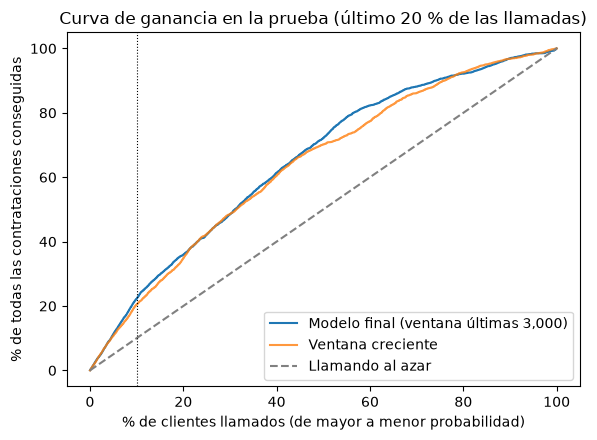

Llamando al 10 % superior se consigue el 22.2 % de todas las contrataciones


In [18]:
# 7. Curva de ganancia: si el banco llama a una fracción de clientes ordenados por el modelo,
#    ¿qué fracción de todos los contratos consigue?
def curva_ganancia(y_t, p):
    orden_prob = np.argsort(-p, kind="stable")
    x = np.arange(1, len(y_t) + 1) / len(y_t)
    return 100 * x, 100 * np.cumsum(y_t[orden_prob]) / y_t.sum()


fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(*curva_ganancia(y_pru_np, prob_pru), label=f"Modelo final (ventana {nombre_ventana(W_elegida)})")
if W_elegida is not None:
    ax.plot(*curva_ganancia(y_pru_np, prob_ventanas[None]), label="Ventana creciente", alpha=0.8)
ax.plot([0, 100], [0, 100], "--", color="gray", label="Llamando al azar")
ax.axvline(100 * FRACCION_LLAMADAS, color="black", lw=0.8, ls=":")
ax.set_xlabel("% de clientes llamados (de mayor a menor probabilidad)")
ax.set_ylabel("% de todas las contrataciones conseguidas")
ax.set_title("Curva de ganancia en la prueba (último 20 % de las llamadas)")
ax.legend()
plt.tight_layout()
Path("figuras").mkdir(exist_ok=True)
plt.savefig("figuras/curva_ganancia.png", dpi=150)
plt.show()
x_g, y_g = curva_ganancia(y_pru_np, prob_pru)
i10 = int(round(FRACCION_LLAMADAS * len(y_pru_np))) - 1
print(f"Llamando al {100*FRACCION_LLAMADAS:.0f} % superior se consigue el {y_g[i10]:.1f} % de todas las contrataciones")

**Comentario.** La validación cruzada eligió la ventana deslizante con las últimas 3,000 llamadas, pero las diferencias entre ventanas fueron mínimas: entre la mejor (0.119) y la peor (0.092, la de 12,000) hay menos de 0.03, mientras que la desviación estándar entre pliegues es de alrededor de 0.1. Es decir, con la validación cruzada no se puede distinguir con seguridad qué ventana es mejor.

Al comparar balancear contra no balancear, encontramos que prácticamente no hay diferencia (con la ventana elegida, las dos opciones llegan a 0.119). Esto tiene sentido porque usamos el modelo para ordenar a los clientes por su probabilidad de contratar: los pesos de `class_weight="balanced"` mueven casi solo el intercepto de la regresión logística, y el orden de los clientes queda casi igual.

Para el banco, esto significa que si llama al 10 % de clientes con mayor probabilidad de contratar, tiene un éxito de alrededor de 70 % (IC 95 %: 67.5 % a 73.2 %), a diferencia de llamar al azar, que es de 31.6 %. Es decir, consigue 2.2 veces más contrataciones por llamada. El AUC-ROC de nuestro modelo (0.72) es menor que el de la consultora (0.98 en su reporte, 0.893 en nuestra reproducción), pero eso es lo esperado: el número de la consultora estaba inflado por las fugas de información, y el nuestro es una estimación honesta de lo que pasará en la siguiente campaña.

Para probar la hipótesis de la ventana deslizante (teoría (e)), comparamos en la prueba todas las ventanas, solo como diagnóstico, porque la elección ya se había hecho con la validación cruzada. Ahí la diferencia sí es clara: la ventana de 3,000 supera a la creciente por 6 puntos en la precisión del 10 % superior, con un intervalo de confianza del bootstrap pareado de [+3.3, +9.1] puntos, que no incluye el cero. La peor en la prueba fue la de 18,000 (0.633). Esto confirma que las llamadas más viejas se parecen poco a las de la siguiente campaña, porque la tasa de contratación cambió mucho con el tiempo.

La gráfica muestra que la curva del modelo siempre está arriba de la línea del azar. Las mejoras más notables respecto a la ventana creciente están alrededor del 10–20 % y del 50–60 % de clientes llamados. En los demás rangos las dos curvas son muy similares. La zona del 10–20 % es la que más le importa al banco, porque es donde va a concentrar sus llamadas.


---
## (e) El experimento del ruido
Con $n = 50$, $5{,}000$ atributos de ruido, $20 + 5b = 45$ atributos seleccionados y un clasificador que tú eliges, repite al menos 50 veces la validación cruzada con la selección hecha:
1. **(i) Antes** de partir en pliegues.
2. **(ii) Dentro** de cada partición (con `Pipeline`).

Grafica las dos distribuciones de la exactitud estimada.

In [19]:
# TODO: Simulación de los 5,000 atributos de ruido y gráfica de ambas distribuciones
